# Лабораторная работа 8 Matplotlib

## Цель лабораторной работы
Освоение библиотеки `matplotlib` для визуализации данных. В ходе работы вы рассмотрите возможность строить линейные графики, столбчатые и круговые диаграммы, а также оформлять оси, легенды и сетки в соответствии с правилами технической документации.

**Требования к оформлению:**
1. Каждая задача должна решаться в объектном стиле (`fig, ax = plt.subplots()`).
2. Все оси должны быть подписаны с указанием единиц измерения.
3. Графики должны сохраняться в файлы с расширением `.png` и разрешением `dpi=150` до вызова `plt.show()`.

## Пример задания 1

Дано: массив среднемесячных температур в Москве за 12 месяцев.

**Требуется:**

- Построить график зависимости температуры от месяца.
- Подписать оси с единицами измерения («Месяц», «Температура, °C»).
- Задать заголовок графика.
- Включить сетку.
- Выделить линию цветом steelblue и толщиной 2.
 - Сохранить график в файл moscow_temp.png с dpi=150.

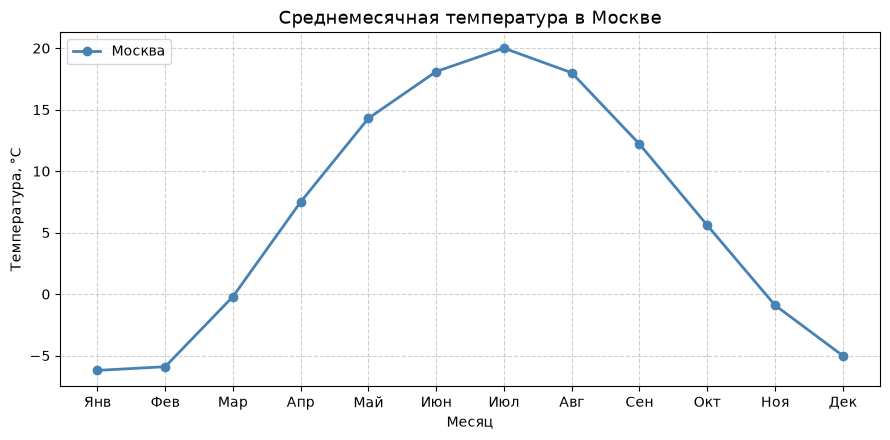

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --- Данные ---------------------------------------------------------------
months_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

# Среднемесячная температура в Москве (примерные значения, °C)
temp = np.array([-6.2, -5.9, -0.2, 7.5, 14.3, 18.1,
                 20.0, 18.0, 12.2, 5.6, -0.9, -5.0])

# --- Построение -----------------------------------------------------------

# размер в дюймах (ширина × высота). При dpi=100 это ~900×450 пикселей на экране.
plt.figure(figsize=(9, 4.5))

plt.plot(months_labels, temp,
         color='steelblue',
         linewidth=2,
         marker='o',
         markersize=6,
         label='Москва')

# --- Оформление -----------------------------------------------------------
plt.title('Среднемесячная температура в Москве', fontsize=13)
plt.xlabel('Месяц')
plt.ylabel('Температура, °C')

plt.grid(True, linestyle='--', alpha=0.6)


plt.legend(loc='upper left')
plt.tight_layout()                          # Подгоняет отступы так, чтобы подписи осей и заголовок не обрезались по краям
plt.savefig('moscow_temp.png', dpi=150)     # Сохраняет текущую фигуру в файл
plt.show()


## Пример задания 2 Свободное падение без сопротивления воздуха

Тело отпущено с высоты $h_0$ без начальной скорости. Ускорение свободного падения $g \approx 9.81$ м/с².

$$h(t) = h_0 - \tfrac{1}{2} g t^2, \qquad v(t) = g t, \qquad t_{\text{пад}} = \sqrt{\dfrac{2 h_0}{g}}$$

При $h_0 = 100$ м время падения $t_{\text{пад}} \approx 4.52$ с.


**Требуется:**

1. Вычислить время падения $t_{\text{пад}}$ по формуле (не «на глазок»).
2. Создать массив моментов времени $t$ от 0 до $t_{\text{пад}}$ (не менее 200 точек).
3. Вычислить $h(t)$ по формуле свободного падения. Отрицательные значения заменить на 0 (использовать `np.maximum`).
4. Построить график $h(t)$ **в объектном стиле** (`fig, ax = plt.subplots(...)`).
5. Оформить график:
   - заголовок с указанием высоты;
   - подписи осей **с единицами измерения** (`Время, с`, `Высота, м`);
   - пределы осей: `x` от 0 до 5 с, `y` от 0 до $h_0 \cdot 1.05$;
   - сетка (`linestyle='--'`, `alpha≈0.6`);
   - горизонтальная линия земли `axhline(0)`;
   - вертикальная линия в момент падения `axvline(t_fall)` и подпись рядом с ней.
6. Сохранить в файл `fall_free.png` с `dpi=150`.

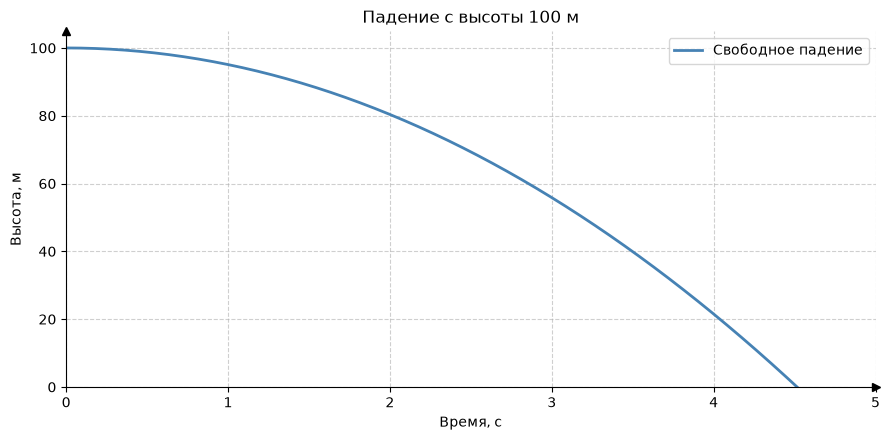

In [11]:
import numpy as np
import matplotlib.pyplot as plt

g  = 9.81
h0 = 100.0

t_fall = np.sqrt(2 * h0 / g)
t = np.linspace(0, t_fall, 200)
h = h0 - 0.5 * g * t**2

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(t, h, color='steelblue', linewidth=2, label='Свободное падение')

ax.set_title(f'Падение с высоты {h0:.0f} м')
ax.set_xlabel('Время, с')
ax.set_ylabel('Высота, м')

ax.set_xlim(0, 5)
ax.set_ylim(0, h0 * 1.05)

ax.grid(True, linestyle='--', alpha=0.6)
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.plot(1, 0, '>k', transform=ax.get_yaxis_transform(), clip_on=False)
ax.plot(0, 1, '^k', transform=ax.get_xaxis_transform(), clip_on=False)

ax.legend(loc='upper right')

fig.tight_layout()
fig.savefig('fall_free.png', dpi=150)
plt.show()

### Пример 3 Гармонические колебания груза на пружине

Груз на пружине совершает свободные гармонические колебания вдоль вертикальной оси. Амплитуда колебаний $A = 5$ см, период $T = 2$ с. В начальный момент времени ($t = 0$) груз находится в крайнем верхнем положении.

Начало координат совмещено с положением равновесия груза, ось $x$ направлена вертикально вверх. Сопротивлением среды и затуханием пренебречь.

**Требуется:**

1. Записать закон колебаний $x(t)$ — зависимость координаты груза от времени.
2. Определить циклическую частоту $\omega$ и максимальную скорость груза.
3. Построить график зависимости координаты $x$ от времени $t$ за два полных периода колебаний.
4. По графику определить моменты времени, когда груз проходит положение равновесия, и моменты, когда он находится в крайних точках.

**Физическая модель.**

При гармонических колебаниях координата тела меняется по закону косинуса (или синуса):

$$x(t) = A \cos(\omega t + \varphi_0)$$

где $\omega = \dfrac{2\pi}{T}$ — циклическая частота, $\varphi_0$ — начальная фаза.

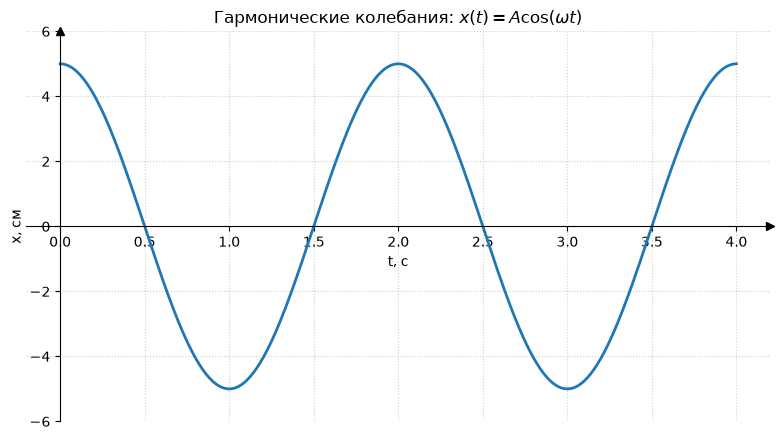

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# параметры колебаний
A = 5.0                          # амплитуда, см
T = 2.0                          # период, с
omega = 2 * np.pi / T            # циклическая частота

t = np.linspace(0, 2 * T, 400)   # два периода
x = A * np.cos(omega * t)        # координата

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(t, x, color='tab:blue', linewidth=2)

# подписи по правилам физики
ax.set_xlabel('t, с')
ax.set_ylabel('x, см')
ax.set_title('Гармонические колебания: $x(t) = A\\cos(\\omega t)$')

# оси через ноль + стрелки
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.plot(1, 0, '>k', transform=ax.get_yaxis_transform(), clip_on=False)
ax.plot(0, 1, '^k', transform=ax.get_xaxis_transform(), clip_on=False)

ax.set_ylim(-A * 1.2, A * 1.2)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Пример 4. Выручка кофейни за две недели

Кофейня работает семь дней в неделю. Владелец записывал дневную выручку в течение двух недель подряд. Значения приведены в тыс. руб.:

| Неделя | Пн | Вт | Ср | Чт | Пт | Сб | Вс |
|---|---|---|---|---|---|---|---|
| 1-я | 12.5 | 11.8 | 13.2 | 14.1 | 18.7 | 22.4 | 19.8 |
| 2-я | 13.1 | 12.4 | 14.5 | 15.2 | 19.8 | 23.6 | 20.5 |

Дни недели нумеруются подряд: понедельник первой недели — позиция 0, воскресенье второй недели — позиция 13. Ось $x$ — номер дня, ось $y$ — выручка в тыс. руб.

**Требуется:**

1. Записать массивы номеров дней $x$ и выручки $y$ — зависимость выручки от дня.
2. Вычислить среднюю выручку за 14 дней $\bar{y}$ и определить, в какой день она максимальна, а в какой — минимальна.
3. Построить график зависимости выручки $y$ от номера дня $x$ за две недели. Ось $x$ подписать названиями дней недели (по две подписи на каждый день — для первой и второй недели соответственно), подписи повернуть на 45°.
4. Отметить на графике горизонтальной пунктирной линией уровень средней выручки и вывести её значение в легенде.
5. Задать пределы осей: по $x$ — от $-0.5$ до $13.5$, по $y$ — от 5 до 30. Включить сетку и легенду.
6. По графику определить, сколько дней выручка была выше средней, и сравнить средние значения двух недель.


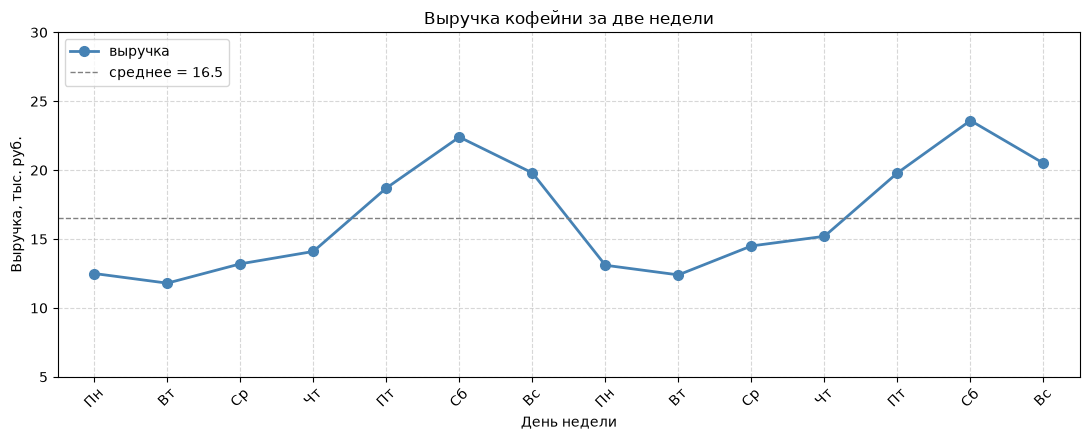

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# --- Данные -------------------------------------------------------------
days    = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'] * 2
revenue = np.array([12.5, 11.8, 13.2, 14.1, 18.7, 22.4, 19.8,
                    13.1, 12.4, 14.5, 15.2, 19.8, 23.6, 20.5])   # тыс. руб.
x        = np.arange(len(days))
mean_rev = revenue.mean()

fig, ax = plt.subplots(figsize=(11, 4.5))

# --- Линия --------------------------------------------------------------
ax.plot(x, revenue, marker='o', color='steelblue',
        linewidth=2, markersize=7, label='выручка')

# --- Средняя ------------------------------------------------------------
ax.axhline(mean_rev, color='gray', linestyle='--', linewidth=1,
           label=f'среднее = {mean_rev:.1f}')


# --- Оси ----------------------------------------------------------------
ax.set_title('Выручка кофейни за две недели')
ax.set_xlabel('День недели')
ax.set_ylabel('Выручка, тыс. руб.')
ax.set_xlim(-0.5, 13.5)
ax.set_ylim(5, 30)
ax.set_xticks(x)
ax.set_xticklabels(days, rotation=45)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

# --- Сохранение ---------------------------------------------------------
fig.tight_layout()
fig.savefig('coffee.png', dpi=150)
plt.show()

### Задание 1.

Метеостанция записывала температуру воздуха (в °C) днём (в 14:00) и ночью (в 02:00) в течение двух недель. Значения приведены в таблице:

| День | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Днём | 5.1 | 6.3 | 4.8 | 7.2 | 9.5 | 8.1 | 6.7 | 5.9 | 7.4 | 8.8 | 10.2 | 9.1 | 7.5 | 6.2 |
| Ночью | −1.2 | 0.3 | −2.1 | 1.5 | 3.8 | 2.4 | 0.9 | −0.4 | 1.8 | 3.2 | 4.6 | 2.9 | 1.1 | −0.3 |

Дни нумеруются подряд: первый день — позиция 1, четырнадцатый — позиция 14. Ось $x$ — номер дня, ось $y$ — температура в °C.

**Требуется:**

1. Записать массивы номеров дней $x$ и температур $y_{\text{день}}$, $y_{\text{ночь}}$.
2. Вычислить средние температуры днём $\bar{y}_{\text{день}}$ и ночью $\bar{y}_{\text{ночь}}$ за две недели. Определить, в какой день разница между днём и ночью максимальна.
3. Построить **обе зависимости на одном графике**:
   - днём — сплошной линией (`'-'`) цвета `tab:orange`, маркеры `'o'`;
   - ночью — штриховой линией (`'--'`) цвета `tab:blue`, маркеры `'s'`.
4. Для каждой серии добавить горизонтальную линию среднего тем же цветом, но пунктиром (`':'`), и вынести значение среднего в подпись:
   ```
   label=f'днём (ср. = {mean_day:.1f} °C)'
   ```
5. Оформить оси: подписи `День` и `Температура, °C`, пределы `x` от 0.5 до 14.5, `y` от −5 до 12, засечки по `x` — каждый день (`set_xticks(x)`), сетка `linestyle='--'`, `alpha=0.5`, легенда `loc='upper left'`.
6. Добавить горизонтальную линию $y = 0$ (граница «мороз / оттепель») тонкой чёрной линией (`linewidth=0.8`).
7. По графику определить: сколько ночей температура была **ниже нуля**? В какие дни суточный ход (разница день − ночь) превышает 6 °C?
8. Сохранить в `weather.png`, `dpi=150`.

In [ ]:
# TODO

### Задание 2

Студент установил на телефон трекер, который две недели записывал два показателя за день: **сколько часов горел экран** и **сколько процентов заряда осталось к концу дня**. Цель — увидеть на графиках, как одно связано с другим.

| День | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Экран, ч | 4.5 | 5.2 | 5.8 | 4.9 | 6.1 | 6.8 | 7.2 | 7.5 | 8.1 | 7.8 | 8.5 | 9.0 | 9.3 | 9.7 |
| Батарея к концу дня, % | 58 | 52 | 48 | 55 | 42 | 38 | 33 | 29 | 22 | 25 | 18 | 14 | 11 | 8 |

Дни нумеруются подряд: первый — 1, четырнадцатый — 14. Ось $x$ на обеих панелях — номер дня. На левой панели ось $y$ — часы экранного времени, на правой — процент заряда к концу дня.

**Требуется:**

1. Записать массивы номеров дней $x$, часов экрана $y_{\text{экр}}$ и заряда $y_{\text{бат}}$.
2. Вычислить средние за две недели: $\bar{y}_{\text{экр}}$ и $\bar{y}_{\text{бат}}$.
3. Создать фигуру с **двумя панелями по горизонтали**:
   ```python
   fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
   ```
4. **Левая панель** (`axes[0]`) — экранное время:
   - `plot(x, y_screen, marker='o', color='tab:blue', linewidth=2, markersize=7)`;
   - горизонтальная линия среднего: `axhline(mean_screen, color='gray', linestyle='--', label=f'среднее = {mean_screen:.1f} ч')`;
   - заголовок `«Экранное время»`;
   - подписи осей `День` / `Экран, часов`;
   - пределы `x` от 0.5 до 14.5, `y` от 0 до 11;
   - засечки по `x` — каждый день (`set_xticks(x)`);
   - сетка `linestyle='--'`, `alpha=0.5`, легенда `loc='upper left'`.
5. **Правая панель** (`axes[1]`) — заряд батареи:
   - `plot(x, y_battery, marker='s', color='tab:green', linewidth=2, markersize=7)`;
   - горизонтальная линия среднего с `label=f'среднее = {mean_battery:.1f} %'`;
   - заголовок `«Заряд к концу дня»`;
   - подписи осей `День` / `Батарея, %`;
   - пределы `x` от 0.5 до 14.5, `y` от 0 до 100;
   - засечки по `x`, сетка, легенда `loc='upper right'`.
6. Стиль обеих панелей — **единый**: одинаковые `figsize`, одинаковый тип сетки.
7. Сохранить в `phone.png`, `dpi=150`, до `plt.show()`.

In [ ]:
# TODO

### Задание 3

В маленьком городке открылись пять пиццерий: «Маргарита Мания», «Пепперони-Парад», «Гавайский Хаос», «Четыре Сыра и Слёзы» и «Веганский Бунт». За неделю они продали соответственно: **23, 45, 56, 78 и 32** пиццы.

Названия пиццерий нумеруются подряд: «Маргарита Мания» — позиция 0, «Веганский Бунт» — позиция 4. Ось $x$ — название пиццерии, ось $y$ — количество проданных пицц.

**Требуется:**

1. Записать массив названий пиццерий `names` и массив проданных пицц `sales`.
2. Создать числовой массив позиций `x = np.arange(len(names))` для столбиков.
3. Найти победителя — пиццерию с максимальными продажами. Использовать `np.argmax(sales)`.
4. Создать фигуру и оси:
   ```python
   fig, ax = plt.subplots(figsize=(10, 5))
   ```
5. Построить **столбчатую диаграмму**:
   - `ax.bar(x, sales, width=0.6, color='steelblue', edgecolor='navy')`. (Поменяйте стиль сами)
6. Оформить оси:
   - заголовок `«Битва пиццерий: продажи за неделю»`;
   - подписи осей `Пиццерия` и `Продано пицц, шт.`;
7. Сохранить в `pizzeria.png`, `dpi=150`, до `plt.show()`.

Настоятельная просьба поработать со стилями

In [ ]:
#TODO

### Задание 4

Супергерой **Алексей** ведёт дневник своей супер-жизни. В сутках 24 часа, и он распределил их так:

*   **8 часов** — спасает мир,
*   **7 часов** — восстанавливает суперсилы во сне,
*   **5 часов** — отдыхает, играя в кибер-квесты,
*   **4 часа** — занимается «другим» (тайные миссии, а возможно, поедание доширака).

Ось X и Y в круговой диаграмме отсутствуют — данные представлены в виде секторов круга, где каждый сектор пропорционален доле категории в общей сумме. Сумма всех часов равна 24.

**Требуется:**

1. Записать список названий активностей `labels` и список затраченных часов `hours`.
2. Создать фигуру и оси:
   ```python
   fig, ax = plt.subplots(figsize=(7, 7))
   ```
3. Построить **круговую диаграмму** с помощью `ax.pie()`:
   - передать данные и подписи;
   - вывести проценты на секторах: `autopct='%1.1f%%'`.
4. Добавить заголовок `«День супергероя Алексея»`.
5. Сохранить в `superhero.png`, `dpi=150`, до `plt.show()`.

In [ ]:
# TODO

### Задание 5

Инженер прокладывает оптоволоконные линии связи между серверами. Сигнал в оптоволокне (свет) движется не с максимальной скоростью света в вакууме, а чуть медленнее из-за стекла.

По законам физики, скорость света в среде вычисляется по формуле:
$$ v = \frac{c}{n} $$
где \(c = 300\,000\) км/с (скорость света в вакууме), а \(n = 1.5\) (показатель преломления стекла).

Инженер замерил время отклика (пинг, Round Trip Time — время туда и обратно) до серверов на разных расстояниях.

| Расстояние \(d\), км | 100 | 500 | 1000 | 3000 | 5000 | 10000 |
|---|---|---|---|---|---|---|
| Измеренный пинг, мс | 1.8 | 5.9 | 11.5 | 32.5 | 53.0 | 104.2 |

Ось \(x\) — расстояние в километрах, ось \(y\) — пинг в миллисекундах.

**Требуется:**

1. Записать массивы расстояний `dist` и измеренного пинга `ping`.
2. **Рассчитать теоретическую скорость сигнала** в оптоволокне:
   - Задать скорость света `c = 300000` (км/с) и показатель преломления `n = 1.5`.
   - Вычислить скорость `v = c / n` (км/с).
3. **Рассчитать теоретический пинг**:
   - Пинг — это время, за которое сигнал проходит туда и обратно. Поэтому формула:
     $$
 P = \frac{2 \cdot d}{v}
$$
   - Внимание на размерности: если \(d\) в км, а \(v\) в км/с, то время получится в секундах. Чтобы перевести в миллисекунды (мс), нужно умножить на 1000.
   - Вычислите теоретический пинг для каждого расстояния из массива `dist` и сохраните в массив `ping_theory`.
4. Создать фигуру и оси: `fig, ax = plt.subplots(figsize=(8, 5))`.
5. Построить **два графика на одних осях**, используя **только `plot()`**:
   - **Измеренный пинг** (точки): используйте `linestyle='None'`, маркер `'o'`, цвет `'crimson'`, подпись `'Измеренный пинг'`.
   - **Теоретический пинг** (прямая линия): используйте `linestyle='-'`, цвет `'steelblue'`, подпись `'Теория (скорость света)'`.
6. Оформить оси:
   - заголовок `«Задержка сигнала в оптоволокне»`;
   - подписи осей `Расстояние, км` и `Пинг (RTT), мс`;
   - пределы осей: по \(x\) — от 0 до 11000, по \(y\) — от 0 до 120;
   - засечки по \(x\) — каждые 2000 км (используйте `np.arange(0, 12001, 2000)`), по \(y\) — каждые 20 мс (`np.arange(0, 121, 20)`);
   - сетка `linestyle='--'`, `alpha=0.5`;
   - легенда `loc='upper left'`.
7. Сохранить в `ping_test.png`, `dpi=150`, до `plt.show()`.

In [19]:
# TODO